# Logistic Regression: Predicting Diabetes (Binary Classification)

**Goal:** Build a simple model that predicts whether a patient has diabetes (`Outcome` = 1) or not (`Outcome` = 0), using medical measurements.

**Dataset:** Pima Indians Diabetes (file `pima_indias_diabetes`, ARFF format)

**Libraries:** `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `joblib`

**Steps in this notebook**
1. Data loading
2. Data visualization
3. Data preprocessing (missing values and imputing)
4. Feature selection
5. Train/test split
6. Model training (Logistic Regression)
7. Model evaluation (accuracy score, confusion matrix)
8. Save and load the model with joblib

**Regression vs. classification:** Regression predicts a *number* (like a price). Classification predicts a *category* (like "diabetes" or "no diabetes"). This notebook is classification.

## Step 0: Import libraries

In [13]:
%pip install seaborn kaggle hub matplotlib seaborn pandas numpy joblib

/Users/jeldy/Documents/LYHENG's DOC/AUPP/Sophomore/Fall - Sophomore 2026 /DSC - Fall/Fall26/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import seaborn as sns
import kagglehub
import os

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


**Guiding Questions**
1. Which imported tool is the model, and which ones are for measuring results?
2. Why do we use `LogisticRegression` here and not `LinearRegression`?

## Step 1: Data Loading

In [15]:
# Download latest version
path = kagglehub.dataset_download("mragpavank/diabetes")

print("Path to dataset files:", path)

Path to dataset files: /Users/jeldy/.cache/kagglehub/datasets/mragpavank/diabetes/versions/1


In [16]:
# Read the CSV file into a pandas DataFrame
csv_path = os.path.join(path, "diabetes.csv")

df = pd.read_csv(csv_path)

In [17]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Note: "DiabetesPedigreeFunction" scores the likelihood of diabetes in a patient based on their family history and genetic relationship to relatives with diabetes

##### Dataset Columns

| Column | Meaning | Range in this file |
|--------|---------|--------------------|
| `Pregnancies` | Number of times the patient has been pregnant. | 0 to 17 |
| `Glucose` | Blood sugar level 2 hours after drinking a sugar solution (an oral glucose tolerance test). Higher values point toward diabetes. | 0 to 199 |
| `BloodPressure` | Diastolic blood pressure (the lower number), in mm Hg. | 0 to 122 |
| `SkinThickness` | Thickness of a skin fold on the back of the arm (triceps), in mm. It is used to estimate body fat. | 0 to 99 |
| `Insulin` | Insulin level in the blood 2 hours after the glucose test, in mu U/ml. | 0 to 846 |
| `BMI` | Body mass index: weight in kg divided by height in meters squared. It measures weight relative to height. | 0 to 67.1 |
| `DiabetesPedigreeFunction` | A score for how likely diabetes is based on family history. A higher score means more relatives with diabetes. | 0.078 to 2.42 |
| `Age` | Age in years. | 21 to 81 |
| `Outcome` | **The target.** `1` means the patient has diabetes, `0` means she does not. | 0 or 1 |

**Guiding Questions**
1. How many patients (rows) and measurements (columns) are there?
2. Which column is the target we want to predict?
3. Why can't we just use `pd.read_csv` on the whole file directly?

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


**Guiding Questions**
1. Are all columns numbers?
2. Does any column have fewer values than the others?

In [19]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


**Interpretation:** This shows the average (mean), smallest (min), and largest (max) value of every column. It helps us spot strange values. For example, a blood pressure of 0 would be impossible for a living person.

**Guiding Questions**
1. What is the average age of the patients?
2. Do any columns have a minimum of 0 that does not make sense?

## Step 2: Data Visualization

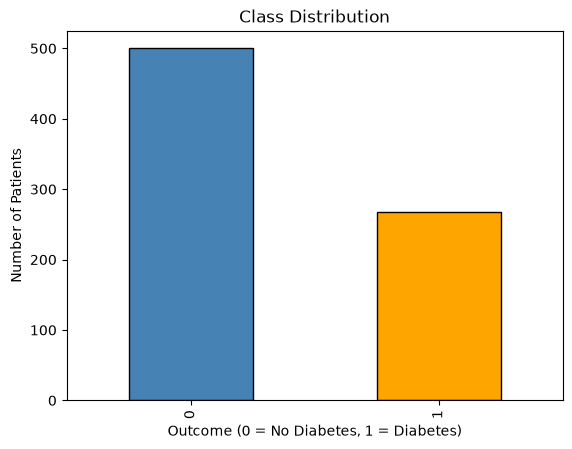

In [20]:
import matplotlib.pyplot as plt

# How many patients have diabetes (1) vs. not (0)?
counts = df["Outcome"].value_counts().sort_index()

counts.plot(kind = "bar", color = ["steelblue", "orange"], edgecolor = "black")
plt.title("Class Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")
plt.show()

**Interpretation:** This bar chart shows how many patients are in each group. There are more people without diabetes than with diabetes, so the classes are a little **imbalanced**. This matters because a model that always says "no diabetes" would already get a fairly high accuracy.

**Guiding Questions**
1. What percent of patients have diabetes?
2. If a model always predicted "No Diabetes", what accuracy would it get?

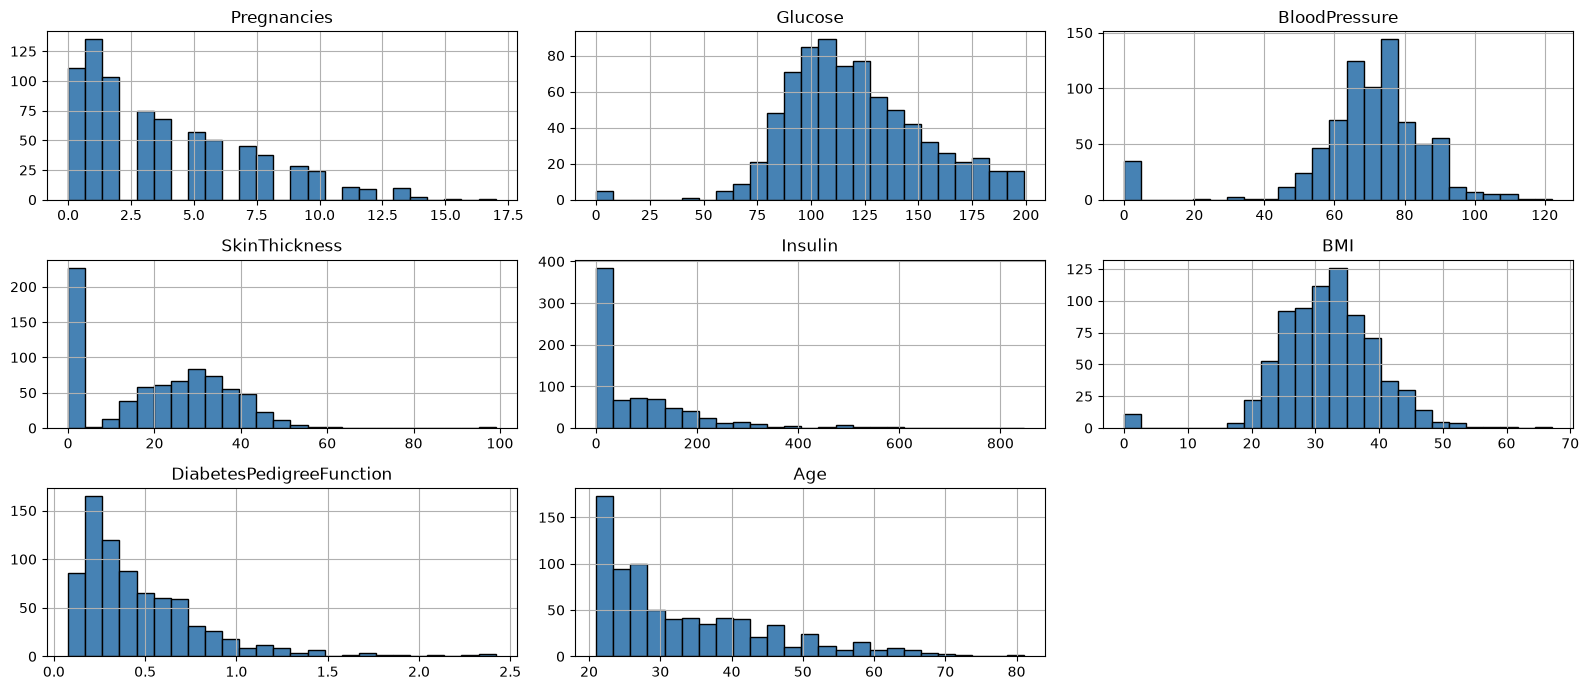

In [21]:
# Histogram of every feature (all columns except the target)
df.drop(columns = "Outcome").hist(bins = 25, figsize = (16, 7), color = "steelblue", edgecolor = "black")
plt.tight_layout()
plt.show()

**Interpretation:** Each small chart shows how the values of one feature are spread. Some features (like `Age` and `Insulin`) are skewed, meaning many small values and a few very large ones.

**Guiding Questions**
1. Which features look skewed to the right?
2. Are there any unusual spikes (for example a tall bar at one value)?

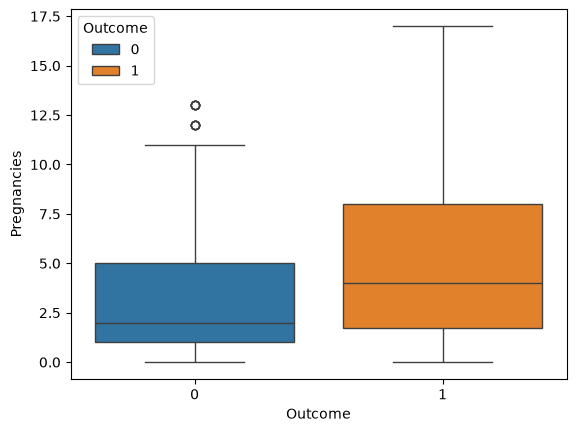

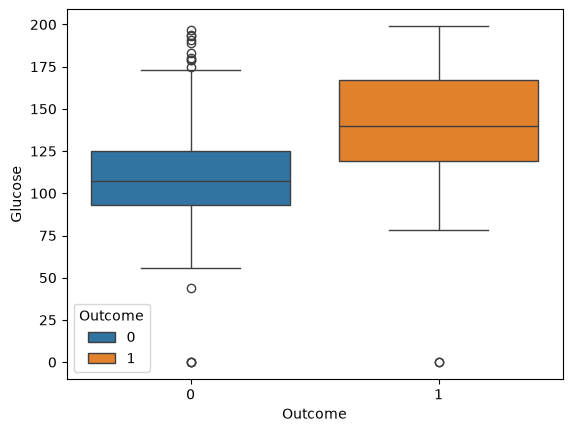

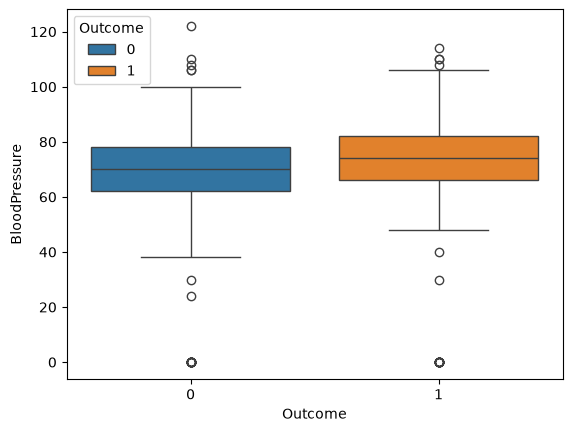

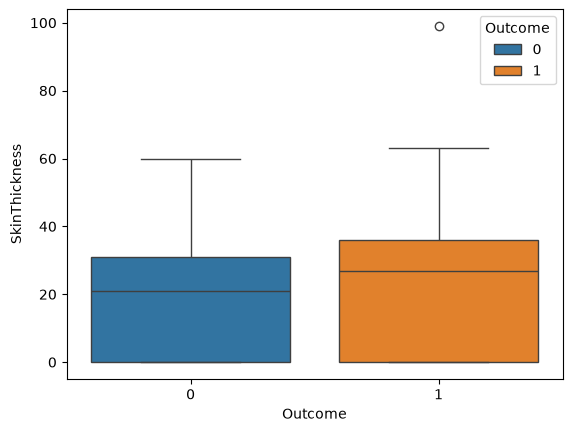

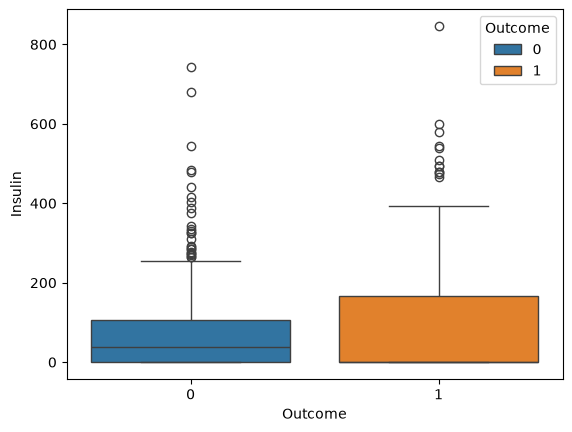

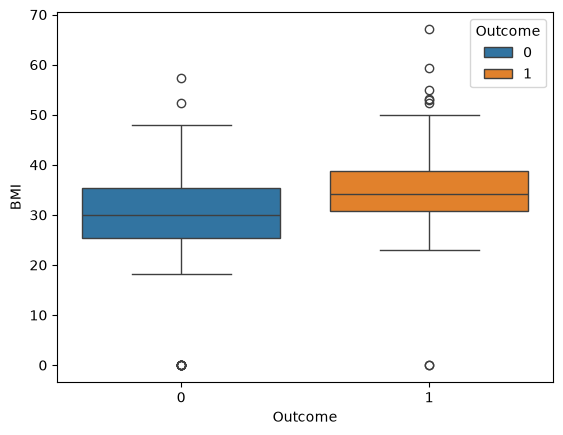

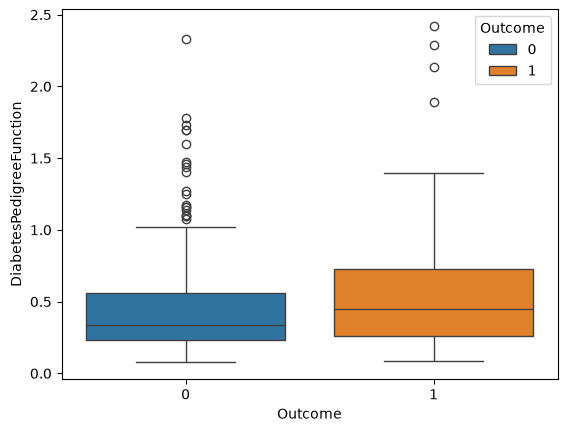

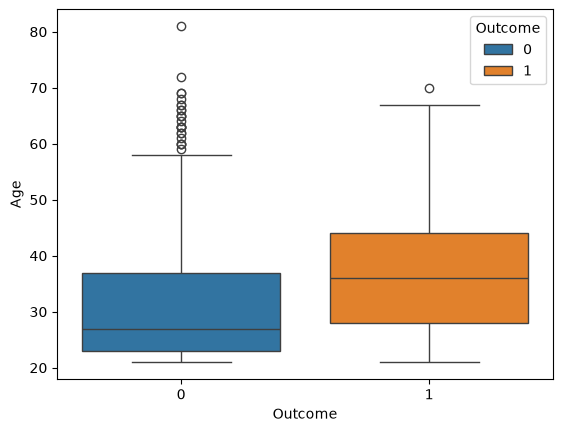

In [22]:
for col in df.columns.drop("Outcome"):
    sns.boxplot(data = df, x = "Outcome", y = col, hue = "Outcome")
    plt.show()

**Interpretation:** A box plot shows the middle value (line inside the box) and the spread of values. If the two boxes are at different heights, that feature helps tell the groups apart. `Glucose` usually shows a clear difference: people with diabetes have higher glucose.

**Guiding Questions**
1. Which feature shows the biggest difference between the two groups?
2. Which feature looks almost the same for both groups?

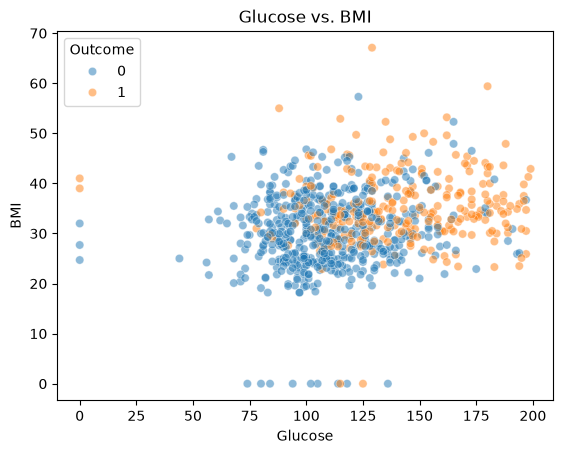

In [23]:
sns.scatterplot(data = df, x = "Glucose", y = "BMI", hue = "Outcome", alpha = 0.5)
plt.title("Glucose vs. BMI")
plt.show()

**Interpretation:** Each dot is a patient. Orange dots (diabetes) tend to appear more on the right side (higher glucose) and higher up (higher BMI). The groups overlap, so the model will not be perfect.

**Guiding Questions**
1. Can you draw a line that separates most red dots from blue dots? (That is what Logistic Regression tries to do.)
2. Why do you think the two groups overlap so much?

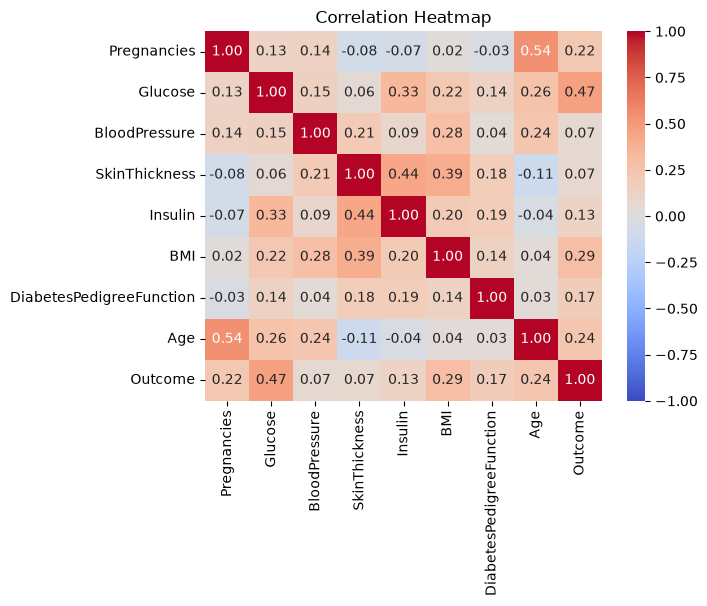

In [24]:
sns.heatmap(df.corr(), annot = True, fmt = ".2f", cmap = "coolwarm", vmin = -1, vmax = 1)
plt.title("Correlation Heatmap")
plt.show()

**Interpretation:** Correlation goes from -1 to +1. Numbers near +1 or -1 mean a strong relationship; numbers near 0 mean a weak one. Look at the `Outcome` row to see which features are most related to diabetes.

**Guiding Questions**
1. Which feature has the highest correlation with `Outcome`?
2. Which two features are strongly related to each other (for example `Age` and `Pregnancies`)?

## Step 3: Data Preprocessing (Missing Values and Imputing)

In [25]:
# 1) Count empty (NaN) values
print("Missing values per column:")
print(df.isnull().sum())

# 2) Count zeros in columns where 0 is impossible
#    (a living person cannot have 0 glucose, 0 blood pressure, 0 BMI, ...)
cols_no_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("\nZeros per column (impossible values):")
print((df[cols_no_zero] == 0).sum())
df[(df[cols_no_zero] == 0).any(axis = 1)]

Missing values per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Zeros per column (impossible values):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
5,5,116,74,0,0,25.6,0.201,30,0
7,10,115,0,0,0,35.3,0.134,29,0
...,...,...,...,...,...,...,...,...,...
761,9,170,74,31,0,44.0,0.403,43,1
762,9,89,62,0,0,22.5,0.142,33,0
764,2,122,70,27,0,36.8,0.340,27,0
766,1,126,60,0,0,30.1,0.349,47,1


**Interpretation:** Missing data can hide in two ways: real empty cells (NaN), or zeros that really mean "not measured". In the original Pima dataset many zeros are hidden missing values. This version of the file was already cleaned by its author, so you should see **0 missing and 0 impossible zeros**. We still run the check because it is a good habit with any new dataset.

**Guiding Questions**
1. How many missing values and impossible zeros did we find?
2. Why is a zero in `Glucose` a problem even though it is not "empty"?

In [26]:
df[cols_no_zero] = df[cols_no_zero].replace(0, np.nan)

df[cols_no_zero] = df[cols_no_zero].fillna(df[cols_no_zero].median())

print("Median of each columns:")
print(df[cols_no_zero].median(), "\n")

print("Zeros left:")
print((df[cols_no_zero] == 0).sum(), "\n")

print("Missing value check after the imputation:")
print((df[cols_no_zero]).isna().sum())

### isna and isnull do the same thing - 

Median of each columns:
Glucose          117.0
BloodPressure     72.0
SkinThickness     29.0
Insulin          125.0
BMI               32.3
dtype: float64 

Zeros left:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64 

Missing value check after the imputation:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


**Interpretation:** We fill every NaN with the **median** of its column. For this file nothing changes, because there was nothing to fix. With the original, uncleaned Pima data, this step would matter a lot.

**Guiding Questions**
1. Why do we use the median and not the mean?
2. What would you do if 50% of a column was missing? Would filling still make sense?
3. To avoid data leakage, should the imputer learn the median from all data or only the training data?

## Step 4: Feature Selection

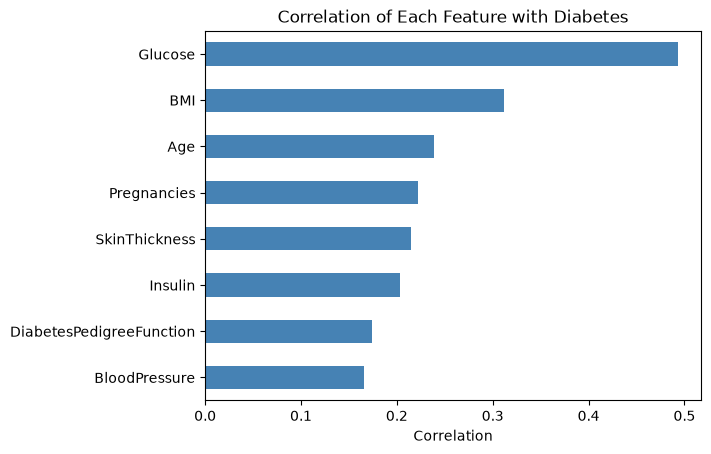

Glucose                     0.492782
BMI                         0.312038
Age                         0.238356
Pregnancies                 0.221898
SkinThickness               0.214873
Insulin                     0.203790
DiabetesPedigreeFunction    0.173844
BloodPressure               0.165723
Name: Outcome, dtype: float64


In [27]:
# Correlation of every numeric column with Outcome (diabetes)
corr = df.corr()
corr_with_target = corr["Outcome"].drop("Outcome")
corr_with_target = corr_with_target.sort_values()

corr_with_target.plot(kind = "barh", color = "steelblue")
plt.title("Correlation of Each Feature with Diabetes")
plt.xlabel("Correlation")
plt.show()

print(corr_with_target.sort_values(ascending = False))

**Interpretation:** This ranks the features by how strongly they relate to diabetes. `Glucose` is the strongest, followed by `Age` and `BMI`. Features near 0 give the model little help. In this cleaned file, every feature has a correlation of at least 0.16, so none of them is very weak.

**Guiding Questions**
1. Which features are most useful? Which are least useful?
2. Is a low correlation always a reason to remove a feature? (Hint: correlation only measures straight-line relationships.)

In [28]:
selected_features = corr_with_target[corr_with_target.abs() >= 0.1].index.tolist()
print("Selected features:", selected_features)

Selected features: ['BloodPressure', 'DiabetesPedigreeFunction', 'Insulin', 'SkinThickness', 'Pregnancies', 'Age', 'BMI', 'Glucose']


In [29]:

X = df[selected_features]   
y = df["Outcome"]           # target (0 or 1)

print("\nX shape:", X.shape)
print("y shape:", y.shape)


X shape: (768, 8)
y shape: (768,)


**Interpretation:** `X` holds the input features and `y` holds the answer. We keep only features with a clear enough relationship to `Outcome`. With the 0.1 cutoff, all 8 features stay, so try a higher cutoff to see the effect. Fewer, better features make the model simpler and easier to understand.

**Guiding Questions**
1. Which features did we keep and which did we drop? (Try a higher cutoff to see some get dropped.)
2. What might happen if we kept features that have nothing to do with the target?

## Step 5: Train/Test Split

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

print("\nDiabetes rate in train: %.1f%%" % (y_train.mean() * 100))
print("Diabetes rate in test : %.1f%%" % (y_test.mean() * 100))

Training set: (614, 8)
Testing set : (154, 8)

Diabetes rate in train: 34.9%
Diabetes rate in test : 35.1%


**Interpretation:** We use 80% of patients to train the model and keep 20% hidden for testing. `stratify=y` makes sure both parts have about the same percent of diabetes cases, which is important when classes are imbalanced.

**Guiding Questions**
1. Are the diabetes rates in train and test similar? Why is that good?
2. What could go wrong if the test set had almost no diabetes patients?

In [31]:
# Scale the features (mean 0, standard deviation 1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn from training data only
X_test_scaled = scaler.transform(X_test)         # apply the same rule to test data

print("Train mean (approx 0):", X_train_scaled.mean(axis=0).round(2))
print("Train std  (approx 1):", X_train_scaled.std(axis=0).round(2))

Train mean (approx 0): [ 0. -0. -0. -0. -0. -0. -0. -0.]
Train std  (approx 1): [1. 1. 1. 1. 1. 1. 1. 1.]


**Interpretation:** Features have very different sizes (`Insulin` can be 800, `DiabetesPedigreeFunction` is under 3). Scaling puts them on the same scale so Logistic Regression learns faster and fairly. We learn the scaling rule from the **training data only** and then apply it to the test data, so the test data stays unseen.

**Guiding Questions**
1. Why do we use `fit_transform` on train but only `transform` on test?
2. What would happen if one feature had numbers 1000 times bigger than the others?

## Step 6: Model Training (Logistic Regression)

In [32]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

print("Model trained!")
print("Intercept:", model.intercept_.round(3))

coef_df = pd.DataFrame({"Feature": selected_features,
                        "Coefficient": model.coef_[0]}).sort_values("Coefficient", ascending=False)
coef_df

Model trained!
Intercept: [-0.872]


,Feature,Coefficient
7,Glucose,1.182511
6,BMI,0.688735
4,Pregnancies,0.377502
1,DiabetesPedigreeFunction,0.233386
5,Age,0.147798
3,SkinThickness,0.028225
0,BloodPressure,-0.044066
2,Insulin,-0.066157


**Interpretation:** Logistic Regression looks at the features, calculates a score, and turns it into a **probability between 0 and 1**. If the probability is 0.5 or more, it predicts "diabetes"; otherwise "no diabetes". A **positive coefficient** pushes the prediction toward diabetes, and a **negative** one pushes it away. Bigger absolute values mean more influence (the features are scaled, so we can compare them).

**Guiding Questions**
1. Which feature has the biggest positive coefficient?
2. Do the signs make sense? (For example, should higher glucose increase the chance of diabetes?)
3. Why is it called "regression" if it does classification?

## Step 7: Model Evaluation (Accuracy and Confusion Matrix)

In [33]:
y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Training accuracy: {train_acc:.4f} ({train_acc*100:.1f}%)")
print(f"Testing accuracy : {test_acc:.4f} ({test_acc*100:.1f}%)")

baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"\nBaseline (always guess the bigger class): {baseline*100:.1f}%")

Training accuracy: 0.7964 (79.6%)
Testing accuracy : 0.7078 (70.8%)

Baseline (always guess the bigger class): 64.9%


**Interpretation:** **Accuracy** = correct predictions / all predictions. We compare it with a **baseline** (always guessing "no diabetes"). A useful model must beat the baseline. If train and test accuracy are close, the model is not badly overfitting.

**Guiding Questions**
1. Is the test accuracy higher than the baseline? By how much?
2. Are train and test accuracy close? What does that mean?
3. Why is accuracy alone sometimes not enough? (Think about imbalanced classes.)

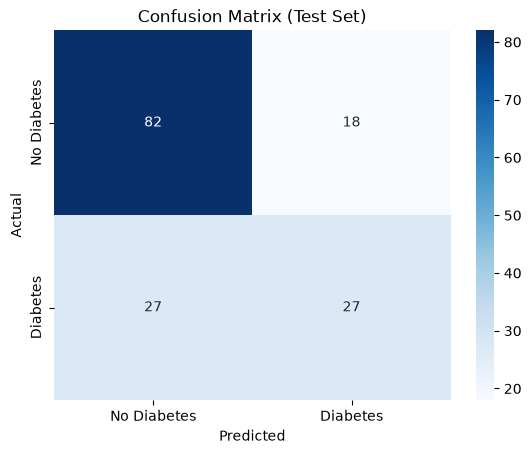

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion matrix on the test set
cm = confusion_matrix(y_test, y_test_pred)

sns.heatmap(
    cm,
    annot = True,
    fmt = "d",
    cmap = "Blues",
    xticklabels = ["No Diabetes", "Diabetes"],
    yticklabels = ["No Diabetes", "Diabetes"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Test Set)")
plt.show()

**Interpretation:** The confusion matrix counts the right and wrong predictions in four boxes:
- **Top-left (True Negative):** no diabetes, predicted no diabetes. Correct.
- **Bottom-right (True Positive):** diabetes, predicted diabetes. Correct.
- **Top-right (False Positive):** no diabetes, but predicted diabetes. A false alarm.
- **Bottom-left (False Negative):** has diabetes, but predicted no diabetes. A missed case.

The numbers on the diagonal (top-left to bottom-right) are the correct ones.

**Guiding Questions**
1. How many patients were predicted correctly? How many wrongly?
2. Which mistake is worse for a hospital: a false positive or a false negative? Why?
3. Can you calculate the accuracy yourself from the four numbers?

In [35]:
# Read the four numbers and compute extra scores by hand
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives : {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives : {tp}")

print("\nAccuracy:", round((tp + tn) / (tp + tn + fp + fn), 4))
print("Of real diabetes cases, the model found: %.1f%%" % (tp / (tp + fn) * 100))
print("When the model says diabetes, it is right: %.1f%%" % (tp / (tp + fp) * 100))

True Negatives : 82
False Positives: 18
False Negatives: 27
True Positives : 27

Accuracy: 0.7078
Of real diabetes cases, the model found: 50.0%
When the model says diabetes, it is right: 60.0%


**Interpretation:** We pull out the four boxes and calculate scores by hand. The first extra score tells us how many real diabetes patients the model **found** (this is called *recall*). The second tells us how often a "diabetes" prediction is **correct** (this is called *precision*).

**Guiding Questions**
1. Does your hand-calculated accuracy match the earlier accuracy?
2. What percent of real diabetes patients did the model miss?
3. How could we find more diabetes cases? (Hint: lower the 0.5 probability threshold. What would happen to false alarms?)

## Step 8: Save and Load the Model with joblib

In [36]:
# Save the trained model AND the scaler (new data must be scaled the same way)
joblib.dump(model, "logistic_regression_diabetes.joblib")
joblib.dump(scaler, "scaler_diabetes.joblib")
print("Saved: logistic_regression_diabetes.joblib and scaler_diabetes.joblib")

# Load them back
loaded_model = joblib.load("logistic_regression_diabetes.joblib")
loaded_scaler = joblib.load("scaler_diabetes.joblib")
print("Loaded successfully!")

Saved: logistic_regression_diabetes.joblib and scaler_diabetes.joblib
Loaded successfully!


**Interpretation:** We save the model with `joblib.dump` and load it with `joblib.load`. We also save the **scaler**, because new patient data must be scaled exactly like the training data. Then we confirm the loaded model gives the same predictions as the original.

**Guiding Questions**
1. Why must we save the scaler as well as the model?
2. What would happen if we gave the loaded model unscaled data?

In [37]:
# Predict for a brand-new patient using the loaded model
new_patient = X_test.iloc[[7]]            # one example row (same columns as training)
print("Patient features:")
print(new_patient, "\n")

new_scaled = loaded_scaler.transform(new_patient)
pred = loaded_model.predict(new_scaled)[0]
prob = loaded_model.predict_proba(new_scaled)[0]

print("Predicted class:", "Diabetes" if pred == 1 else "No Diabetes")
print(f"Probability of no diabetes: {prob[0]:.2f}")
print(f"Probability of diabetes   : {prob[1]:.2f}")
print("Actual class   :", "Diabetes" if y_test.iloc[7] == 1 else "No Diabetes")

Patient features:
     BloodPressure  DiabetesPedigreeFunction  Insulin  SkinThickness  \
408           74.0                     1.191    125.0           29.0   

     Pregnancies  Age   BMI  Glucose  
408            8   39  25.9    197.0   

Predicted class: Diabetes
Probability of no diabetes: 0.08
Probability of diabetes   : 0.92
Actual class   : Diabetes


**Interpretation:** This is how the model is used in real life. We load the saved files, scale the new patient's data, and get a prediction plus the **probability**. The probability tells us how confident the model is.

**Guiding Questions**
1. Was the prediction correct? How confident was the model?
2. Why might a doctor prefer to see the probability and not only "Yes/No"?

## Summary

| Step | What we did |
|------|-------------|
| Data loading | Read the CSV file with `pandas` |
| Visualization | Class bar chart, histograms, box plots, scatter plot, correlation heatmap |
| Preprocessing | Checked for NaN and impossible zeros, imputed with the median |
| Feature selection | Kept all 8 features |
| Split | 80% train, 20% test (stratified), then scaling |
| Training | `LogisticRegression` |
| Evaluation | Accuracy, confusion matrix, recall and precision |
| Saving | `joblib.dump` and `joblib.load` for model and scaler |

## Try it yourself
1. Keep only the features with a correlation of at least 0.3 with `Outcome` (fewer features). Does accuracy go up or down?

   ```python
   corr_with_target = df.corr()["Outcome"].drop("Outcome")
   selected_features = corr_with_target[corr_with_target.abs() >= 0.3].index.tolist()
   print("Selected features:", selected_features)

   X = df[selected_features]
   ```

   Then repeat the split, scaling, training, and evaluation with this new `X`, and compare the accuracy.

2. Change `test_size` to 0.3. What happens to the confusion matrix?

   ```python
   X_train, X_test, y_train, y_test = train_test_split(
       X, y, test_size = 0.3, random_state = 42, stratify = y
   )
   ```

   Then repeat the scaling, training, and confusion matrix. The test set is bigger, so the counts in the matrix get bigger too. Compare the percentages, not just the counts.

3. Use `model.predict_proba` and a threshold of 0.3 instead of 0.5. How do false positives and false negatives change?

   ```python
   from sklearn.metrics import confusion_matrix

   y_proba = model.predict_proba(X_test_scaled)[:, 1]   # chance of diabetes
   y_pred_03 = (y_proba >= 0.3).astype(int)

   print(confusion_matrix(y_test, y_pred_03))
   ```

   `predict_proba` gives the chance of diabetes for each patient. `[:, 1]` keeps only the chance of class 1. A lower threshold predicts "diabetes" more often, so false negatives usually go down and false positives go up.

4. Remove `StandardScaler`. Does the model still train? Does accuracy change?

   ```python
   from sklearn.linear_model import LogisticRegression
   from sklearn.metrics import accuracy_score

   model_no_scale = LogisticRegression(max_iter = 1000)
   model_no_scale.fit(X_train, y_train)

   y_pred_no_scale = model_no_scale.predict(X_test)
   print("Accuracy without scaling:", accuracy_score(y_test, y_pred_no_scale))
   ```

   Compare this with the accuracy of the scaled model. Without scaling, `max_iter` may need to be raised to avoid a convergence warning.

5. Use a more advanced model like random forest. Does it beat logistic regression?

   ```python
   from sklearn.ensemble import RandomForestClassifier
   from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

   rf_model = RandomForestClassifier(n_estimators = 100, random_state = 42)
   rf_model.fit(X_train, y_train)

   rf_pred = rf_model.predict(X_test)

   print("Random forest accuracy:", accuracy_score(y_test, rf_pred))
   print("Random forest recall  :", recall_score(y_test, rf_pred))
   print(confusion_matrix(y_test, rf_pred))
   ```

   The steps are the same as before: create the model, `fit`, then `predict`. Random forest does not need scaling, so use `X_train` and `X_test`, not the scaled versions. Compare the accuracy and the recall with the logistic regression results. To see which features the forest relies on most, print them:

   ```python
   import pandas as pd

   importances = pd.Series(rf_model.feature_importances_, index = X.columns)
   print(importances.sort_values(ascending = False))
   ```

## Limitation
Our logistic regression model reaches an accuracy of only about 75% to 78%. Here is why:

- **It draws a straight boundary.** Logistic regression separates the two groups with a straight line (a flat plane in many dimensions). Real risk of diabetes can depend on combinations of features, such as high glucose together with high BMI, which a straight boundary cannot capture.
- **A lot of data was missing.** About 30% of `SkinThickness` and about 49% of `Insulin` were recorded as impossible zeros. Filling them all with the median removes real differences between patients and adds noise.
- **The dataset is small.** With 768 patients, the test set has only about 154 rows, so one different prediction moves the accuracy by a noticeable amount and the scores are not very stable.
- **The classes are uneven.** About 65% of patients have no diabetes, so the baseline accuracy is already about 65%. At a threshold of 0.5, the model misses many patients who do have diabetes, so recall for the diabetes class is lower than the accuracy suggests.
- **The features are limited and noisy.** Only 8 measurements are available. Diet, exercise, and family details beyond the pedigree score are not included, and measurements such as insulin vary a lot from day to day.
- **Outliers affect the fit.** A few extreme values (for example, in `Insulin`) can pull the model away from the typical patient.
- **The data comes from one group.** All patients are women at least 21 years old of Pima Indian heritage, so the model may not work as well for other groups.